# 02 — Visualisasi Data Kunjungan Posyandu Kota Banjarmasin (2023–2026)

**Mata kuliah:** Visualisasi Data · **Nama:** Muhammad Dzul Fathi Ahyan · **NIM:** 2410817210011

Notebook ini membuat ulang visualisasi dashboard Tableau dengan Python (matplotlib), supaya hasil
analisis bisa direproduksi dan didokumentasikan di GitHub. Setiap grafik menjawab satu insight.

| Gambar | Insight |
|---|---|
| 01 Tren % dilayani bulanan | Insight 2: capaian balita turun setelah sasaran diperluas |
| 02 Komposisi kunjungan | Insight 1: kunjungan naik, tetapi dari kategori baru |
| 03 Scatter beban vs balita | Insight 3: beban kategori baru berhubungan dengan capaian balita |
| 04 Gap sasaran | Insight 4: sasaran yang belum terlayani |
| 05 Kecamatan | Insight 5: perbedaan penurunan antarkecamatan |
| 06–07 Heatmap & boxplot | Pendukung (detail & kualitas data) |
| 00 Dashboard | Ringkasan satu halaman |

**Prasyarat:** jalankan `01_cleaning_posyandu.ipynb` terlebih dahulu. Notebook ini hanya membaca hasilnya:
- `data/processed/posyandu_long_clean.csv`
- `outputs/tables/beban_vs_balita.csv`

Gambar disimpan ke `outputs/figures/`.

> ⚠️ Data bersifat privat dan **tidak diunggah ke GitHub**. Sebelum commit, kosongkan output notebook
> (*Kernel → Restart & Clear Output*).

## 0. Setup & memuat data hasil cleaning

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter, PercentFormatter

ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent

CLEAN_PATH  = ROOT / "data" / "processed" / "posyandu_long_clean.csv"
BEBAN_PATH  = ROOT / "outputs" / "tables" / "beban_vs_balita.csv"
FIG_DIR     = ROOT / "outputs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

for p in [CLEAN_PATH, BEBAN_PATH]:
    assert p.exists(), f"File tidak ditemukan: {p}\nJalankan dulu notebook 01_cleaning_posyandu.ipynb"

clean = pd.read_csv(CLEAN_PATH, parse_dates=["Tanggal"])
beban = pd.read_csv(BEBAN_PATH)
print("Data dimuat:", clean.shape, beban.shape)

Data dimuat: (96220, 21) (969, 10)


## 1. Gaya visual & warna
Warna per kategori dipakai sama di Tableau, PPT, dan poster. Layanan inti (balita & ibu hamil) memakai warna paling kuat.

In [3]:
# Warna konsisten per kategori (sama dengan Tableau, PPT, poster).
# Urutan ini sudah dicek aman untuk buta warna pada pasangan yang bersebelahan.
KATEGORI = ["Bayi Balita", "Ibu Hamil", "Usia Sekolah dan Remaja", "Usia Produktif", "Lansia"]
WARNA = {
    "Bayi Balita":             "#eb6834",  # oranye  - layanan inti (fokus cerita)
    "Ibu Hamil":               "#6250d6",  # ungu    - layanan inti
    "Usia Sekolah dan Remaja": "#1baf7a",  # toska   - kategori baru
    "Usia Produktif":          "#2a78d6",  # biru    - kategori baru
    "Lansia":                  "#e87ba4",  # magenta - kategori baru
}
LABEL_PENDEK = {"Usia Sekolah dan Remaja": "Usia Sekolah & Remaja"}
SURFACE, TEXT_1, TEXT_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
ABU = "#a3a29c"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.edgecolor": GRID, "axes.labelcolor": TEXT_2, "axes.titlecolor": TEXT_1,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": TEXT_2, "ytick.color": TEXT_2,
    "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": False, "legend.labelcolor": TEXT_2,
})

def ribu(x, _=None):
    return f"{x/1e6:.1f} jt".replace(".", ",") if abs(x) >= 1e6 else f"{x/1e3:.0f} rb"

def id_num(x, d=1):
    # Format angka gaya Indonesia: 1.234,5
    s = f"{x:,.{d}f}"
    return s.replace(",", "X").replace(".", ",").replace("X", ".")

def pct(cak, sas):
    return cak / sas.replace(0, np.nan) * 100

def subjudul(ax, teks):
    ax.text(0, 1.02, teks, transform=ax.transAxes, color=TEXT_2, fontsize=9.5, va="bottom")

def simpan_fig(fig, nama):
    path = FIG_DIR / nama
    fig.savefig(path, dpi=200, bbox_inches="tight")
    print("✔", path.relative_to(ROOT))

JAN_AGU = clean[clean["BulanNo"] <= 8]

## 2. Agregasi & angka KPI
Persentase agregat = Σ Cakupan ÷ Σ Sasaran × 100. Perbandingan antartahun memakai Januari–Agustus.

In [4]:
# Agregat yang dipakai banyak chart
th_kat = JAN_AGU.groupby(["Tahun", "Kategori"])[["Sasaran", "Cakupan"]].sum().reset_index()
th_kat["Pct"] = pct(th_kat["Cakupan"], th_kat["Sasaran"])
th_kat["Kontribusi"] = th_kat["Cakupan"] / th_kat.groupby("Tahun")["Cakupan"].transform("sum") * 100

bulanan = clean.groupby(["Tanggal", "Kategori"])[["Sasaran", "Cakupan"]].sum().reset_index()
bulanan["Pct"] = pct(bulanan["Cakupan"], bulanan["Sasaran"])

kec = JAN_AGU[JAN_AGU["Kategori"] == "Bayi Balita"].groupby(["Kecamatan", "Tahun"])[["Sasaran", "Cakupan"]].sum()
kec = kec.unstack("Tahun")

# Angka KPI (dipakai di judul & insight agar konsisten dengan laporan)
tot = JAN_AGU.groupby("Tahun")[["Sasaran", "Cakupan"]].sum()
K = {
    "kunjungan_2023": tot.loc[2023, "Cakupan"],
    "kunjungan_2026": tot.loc[2026, "Cakupan"],
    "naik_kunjungan": (tot.loc[2026, "Cakupan"] / tot.loc[2023, "Cakupan"] - 1) * 100,
    "balita_2024": th_kat.query("Tahun==2024 and Kategori=='Bayi Balita'")["Pct"].item(),
    "balita_2026": th_kat.query("Tahun==2026 and Kategori=='Bayi Balita'")["Pct"].item(),
    "bumil_2024":  th_kat.query("Tahun==2024 and Kategori=='Ibu Hamil'")["Pct"].item(),
    "bumil_2026":  th_kat.query("Tahun==2026 and Kategori=='Ibu Hamil'")["Pct"].item(),
    "gap_2026":    tot.loc[2026, "Sasaran"] - tot.loc[2026, "Cakupan"],
    "pct_2026":    tot.loc[2026, "Cakupan"] / tot.loc[2026, "Sasaran"] * 100,
    "posyandu_aktif_2026": JAN_AGU[(JAN_AGU["Tahun"] == 2026) & JAN_AGU["Aktif_Melayani"]]["Posyandu_ID"].nunique(),
    "posyandu_2023": JAN_AGU[JAN_AGU["Tahun"] == 2023]["Posyandu_ID"].nunique(),
}
b26 = beban[beban["Tahun"] == 2026]
K["r_2026"] = b26["Porsi_Kategori_Baru"].corr(b26["Pct_Dilayani_Balita"])
q = b26.groupby("Kuartil_Beban")["Pct_Dilayani_Balita"].median()
K["q1"], K["q4"] = q["Q1 Rendah"], q["Q4 Tinggi"]
pd.Series(K).round(2)

kunjungan_2023          171623.00
kunjungan_2026          305931.00
naik_kunjungan              78.26
balita_2024                 74.22
balita_2026                 52.12
bumil_2024                  72.46
bumil_2026                  51.55
gap_2026               1958550.00
pct_2026                    13.51
posyandu_aktif_2026        482.00
posyandu_2023              395.00
r_2026                      -0.29
q1                          61.14
q4                          42.13
dtype: float64

## 3. Gambar 1 — Tren % dilayani bulanan (Insight 2)

✔ outputs\figures\01_tren_pct_dilayani.png


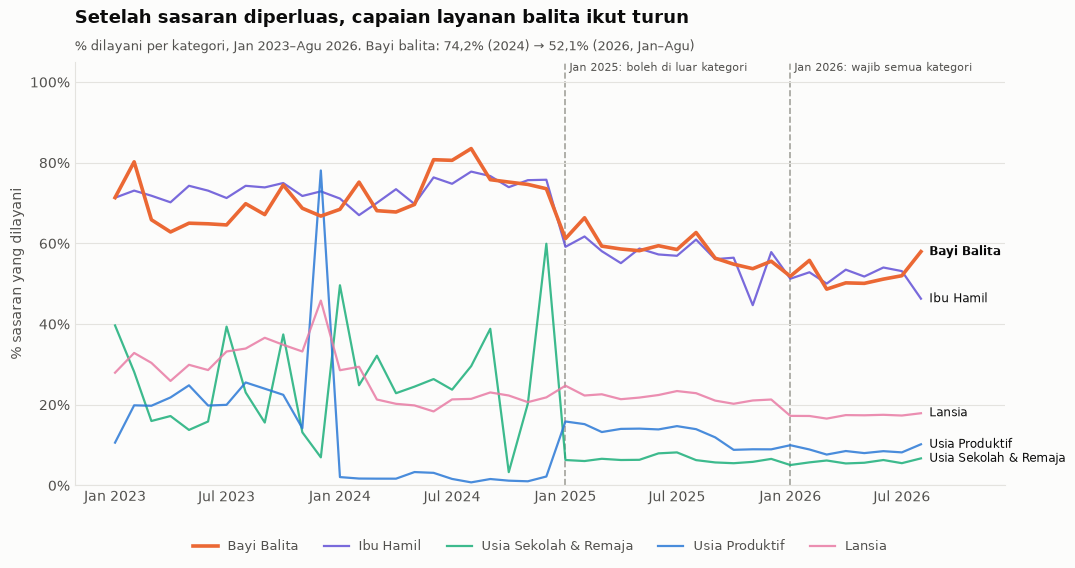

In [5]:
# Gambar 1 - Insight 2: tren % dilayani bulanan per kategori
def plot_tren(ax, ringkas=False):
    for k in KATEGORI:
        d = bulanan[bulanan["Kategori"] == k].sort_values("Tanggal")
        utama = k == "Bayi Balita"
        ax.plot(d["Tanggal"], d["Pct"], color=WARNA[k], lw=2.6 if utama else 1.6,
                alpha=1 if utama else 0.85, zorder=3 if utama else 2, label=LABEL_PENDEK.get(k, k))
        if not ringkas:
            last = d.iloc[-1]
            ax.annotate(LABEL_PENDEK.get(k, k), (last["Tanggal"], last["Pct"]), xytext=(6, 0),
                        textcoords="offset points", va="center", fontsize=8.5, color=TEXT_1,
                        fontweight="bold" if utama else "normal")
    for tgl, teks in [("2025-01-01", "Jan 2025: boleh di luar kategori"),
                      ("2026-01-01", "Jan 2026: wajib semua kategori")]:
        ax.axvline(pd.Timestamp(tgl), color=ABU, ls="--", lw=1.2, zorder=1)
        ax.text(pd.Timestamp(tgl), 1.0, " " + teks, transform=ax.get_xaxis_transform(),
                fontsize=8, color=TEXT_2, va="top")
    ax.set_ylim(0, 105)
    ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: mdates.num2date(x).strftime("%b %Y")
                                               .replace("Jul", "Jul").replace("Jan", "Jan")))
    ax.grid(axis="x", visible=False)
    ax.set_ylabel("% sasaran yang dilayani")

fig, ax = plt.subplots(figsize=(12, 5.5))
plot_tren(ax)
ax.set_title("Setelah sasaran diperluas, capaian layanan balita ikut turun", pad=28)
subjudul(ax, f"% dilayani per kategori, Jan 2023–Agu 2026. Bayi balita: {id_num(K['balita_2024'])}% (2024) "
             f"→ {id_num(K['balita_2026'])}% (2026, Jan–Agu)")
ax.set_xlim(right=pd.Timestamp("2026-12-15"))
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.1), fontsize=9)
simpan_fig(fig, "01_tren_pct_dilayani.png")
plt.show()

## 4. Gambar 2 — Komposisi kunjungan per tahun (Insight 1)

✔ outputs\figures\02_komposisi_kunjungan.png


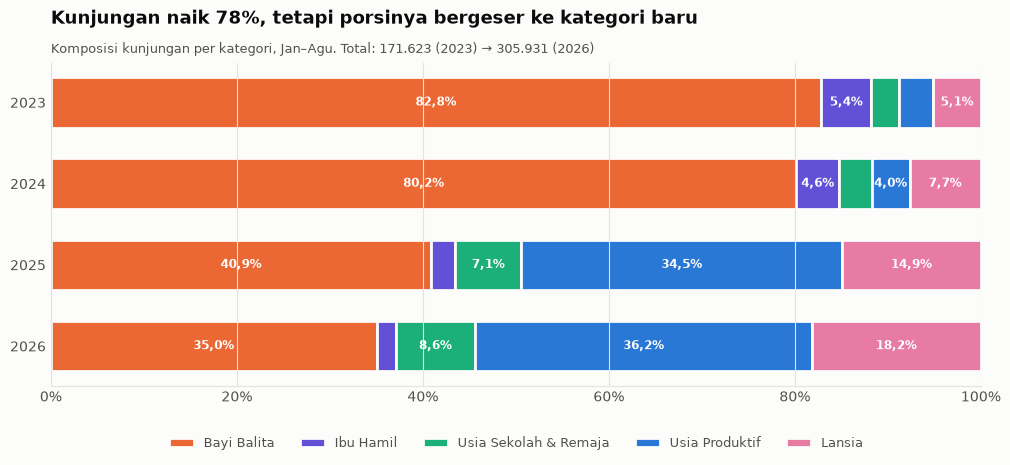

In [6]:
# Gambar 2 - Insight 1: komposisi kunjungan per tahun (100%)
def plot_komposisi(ax, label_min=4):
    tahun = [2023, 2024, 2025, 2026]
    kiri = np.zeros(len(tahun))
    for k in KATEGORI:
        v = th_kat[th_kat["Kategori"] == k].set_index("Tahun").loc[tahun, "Kontribusi"].values
        ax.barh([str(t) for t in tahun], v, left=kiri, color=WARNA[k], height=0.62,
                edgecolor=SURFACE, linewidth=2, label=LABEL_PENDEK.get(k, k))
        for i, (x0, w) in enumerate(zip(kiri, v)):
            if w >= label_min:
                ax.text(x0 + w / 2, i, f"{id_num(w)}%", ha="center", va="center", fontsize=8.5,
                        color="white", fontweight="bold")
        kiri += v
    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.grid(axis="y", visible=False)

fig, ax = plt.subplots(figsize=(12, 4.2))
plot_komposisi(ax)
ax.set_title(f"Kunjungan naik {id_num(K['naik_kunjungan'],0)}%, tetapi porsinya bergeser ke kategori baru", pad=28)
subjudul(ax, f"Komposisi kunjungan per kategori, Jan–Agu. Total: {id_num(K['kunjungan_2023'],0)} (2023) "
             f"→ {id_num(K['kunjungan_2026'],0)} (2026)")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.12), fontsize=9)
simpan_fig(fig, "02_komposisi_kunjungan.png")
plt.show()

## 5. Gambar 3 — Beban kategori baru vs capaian balita (Insight 3)

✔ outputs\figures\03_scatter_beban_vs_balita.png


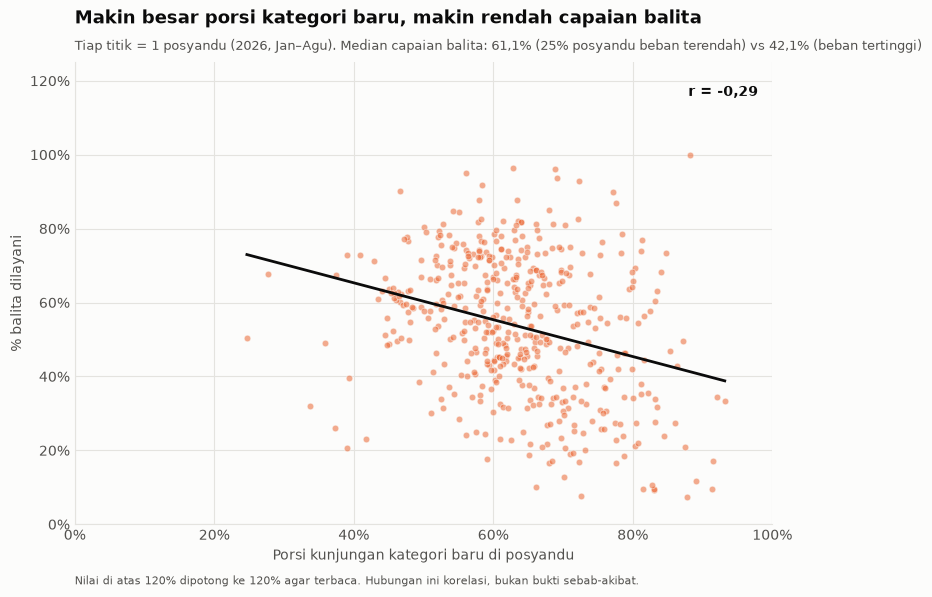

In [7]:
# Gambar 3 - Insight 3: beban kategori baru vs capaian balita per posyandu (2026)
def plot_scatter(ax, ringkas=False):
    d = b26.copy()
    y = d["Pct_Dilayani_Balita"].clip(upper=120)
    ax.scatter(d["Porsi_Kategori_Baru"], y, s=22 if not ringkas else 12, color=WARNA["Bayi Balita"],
               alpha=0.55, edgecolor=SURFACE, linewidth=0.6, zorder=2)
    a, b = np.polyfit(d["Porsi_Kategori_Baru"], d["Pct_Dilayani_Balita"], 1)
    xs = np.linspace(d["Porsi_Kategori_Baru"].min(), d["Porsi_Kategori_Baru"].max(), 50)
    ax.plot(xs, a * xs + b, color=TEXT_1, lw=2, zorder=3)
    ax.text(0.98, 0.95, f"r = {id_num(K['r_2026'], 2)}", transform=ax.transAxes, ha="right",
            va="top", fontsize=10, color=TEXT_1, fontweight="bold")
    ax.set_xlim(0, 100); ax.set_ylim(0, 125)
    ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.set_xlabel("Porsi kunjungan kategori baru di posyandu")
    ax.set_ylabel("% balita dilayani")

fig, ax = plt.subplots(figsize=(9, 6))
plot_scatter(ax)
ax.set_title("Makin besar porsi kategori baru, makin rendah capaian balita", pad=28)
subjudul(ax, f"Tiap titik = 1 posyandu (2026, Jan–Agu). Median capaian balita: {id_num(K['q1'])}% "
             f"(25% posyandu beban terendah) vs {id_num(K['q4'])}% (beban tertinggi)")
ax.text(0, -0.13, "Nilai di atas 120% dipotong ke 120% agar terbaca. Hubungan ini korelasi, bukan bukti sebab-akibat.",
        transform=ax.transAxes, fontsize=8, color=TEXT_2)
simpan_fig(fig, "03_scatter_beban_vs_balita.png")
plt.show()

## 6. Gambar 4 — Gap sasaran vs dilayani 2026 (Insight 4)

✔ outputs\figures\04_gap_sasaran.png


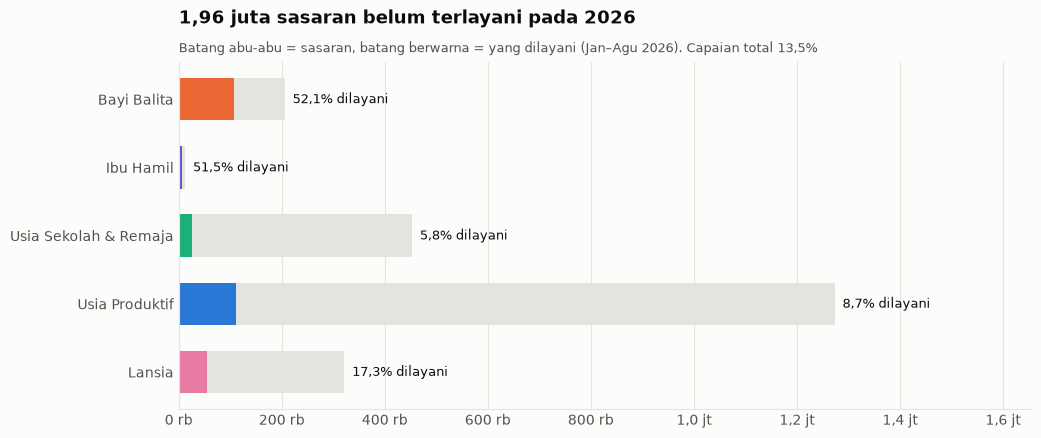

In [8]:
# Gambar 4 - Insight 4: gap sasaran vs cakupan per kategori (2026)
def plot_gap(ax, ringkas=False):
    d = th_kat[th_kat["Tahun"] == 2026].set_index("Kategori").loc[KATEGORI[::-1]]
    ylab = [LABEL_PENDEK.get(k, k) for k in d.index]
    ax.barh(ylab, d["Sasaran"], color=GRID, height=0.62, label="Sasaran")
    ax.barh(ylab, d["Cakupan"], color=[WARNA[k] for k in d.index], height=0.62, label="Dilayani")
    for i, (s, p_) in enumerate(zip(d["Sasaran"], d["Pct"])):
        ax.text(s, i, f"  {id_num(p_)}% dilayani", va="center", fontsize=8.5 if ringkas else 9, color=TEXT_1)
    ax.set_xlim(0, d["Sasaran"].max() * (1.45 if ringkas else 1.3))
    ax.xaxis.set_major_formatter(FuncFormatter(ribu))
    ax.grid(axis="y", visible=False)

fig, ax = plt.subplots(figsize=(11, 4.5))
plot_gap(ax)
ax.set_title(f"{id_num(K['gap_2026']/1e6, 2)} juta sasaran belum terlayani pada 2026", pad=28)
subjudul(ax, f"Batang abu-abu = sasaran, batang berwarna = yang dilayani (Jan–Agu 2026). "
             f"Capaian total {id_num(K['pct_2026'])}%")
simpan_fig(fig, "04_gap_sasaran.png")
plt.show()

## 7. Gambar 5 — Perubahan kunjungan balita per kecamatan (Insight 5)

✔ outputs\figures\05_kecamatan_balita.png


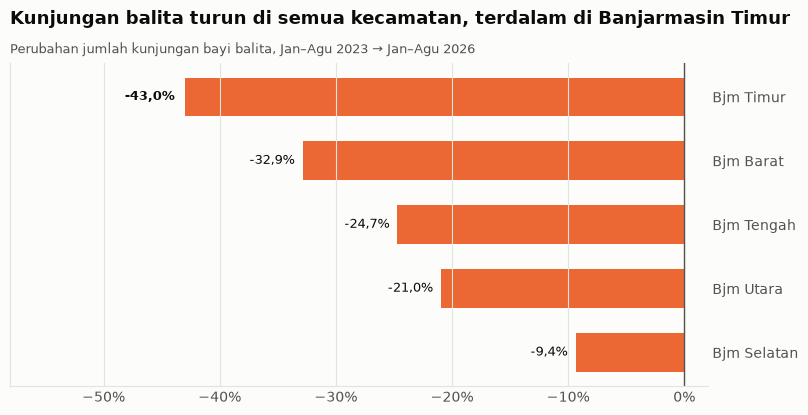

In [9]:
# Gambar 5 - Insight 5: perubahan kunjungan balita per kecamatan 2023 -> 2026
def plot_kecamatan(ax):
    ch = ((kec[("Cakupan", 2026)] / kec[("Cakupan", 2023)] - 1) * 100).sort_values()
    lab = [s.replace("Banjarmasin ", "Bjm ") for s in ch.index]
    ax.barh(lab, ch.values, color=WARNA["Bayi Balita"], height=0.6)
    for i, v in enumerate(ch.values):
        ax.text(v, i, f"{id_num(v)}%  ", ha="right", va="center", fontsize=9, color=TEXT_1,
                fontweight="bold" if i == 0 else "normal")
    ax.axvline(0, color=TEXT_2, lw=1)
    ax.set_xlim(ch.min() * 1.35, 2)
    ax.invert_yaxis()
    ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.grid(axis="y", visible=False)
    ax.yaxis.tick_right()
    return ch

fig, ax = plt.subplots(figsize=(9, 4.2))
ch = plot_kecamatan(ax)
ax.set_title(f"Kunjungan balita turun di semua kecamatan, terdalam di {ch.index[0]}", pad=28)
subjudul(ax, "Perubahan jumlah kunjungan bayi balita, Jan–Agu 2023 → Jan–Agu 2026")
simpan_fig(fig, "05_kecamatan_balita.png")
plt.show()

## 8. Gambar 6 — Heatmap % dilayani (pendukung)

✔ outputs\figures\06_heatmap_pct_dilayani.png


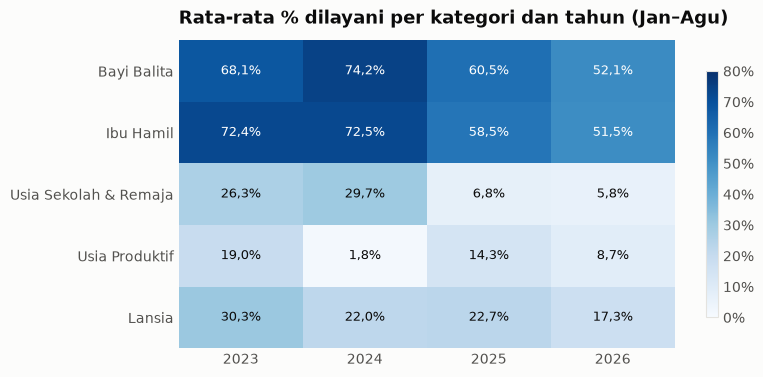

In [10]:
# Gambar 6 (pendukung) - heatmap % dilayani kategori x tahun
hm = th_kat.pivot(index="Kategori", columns="Tahun", values="Pct").loc[KATEGORI]
fig, ax = plt.subplots(figsize=(8, 4))
im = ax.imshow(hm.values, cmap="Blues", vmin=0, vmax=80, aspect="auto")
ax.set_xticks(range(hm.shape[1]), hm.columns)
ax.set_yticks(range(hm.shape[0]), [LABEL_PENDEK.get(k, k) for k in hm.index])
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        v = hm.values[i, j]
        ax.text(j, i, f"{id_num(v)}%", ha="center", va="center", fontsize=9,
                color="white" if v > 45 else TEXT_1)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title("Rata-rata % dilayani per kategori dan tahun (Jan–Agu)", pad=12)
fig.colorbar(im, ax=ax, format=PercentFormatter(decimals=0), shrink=0.8)
simpan_fig(fig, "06_heatmap_pct_dilayani.png")
plt.show()

## 9. Gambar 7 — Sebaran % dilayani balita antarposyandu (pendukung)

✔ outputs\figures\07_boxplot_balita.png


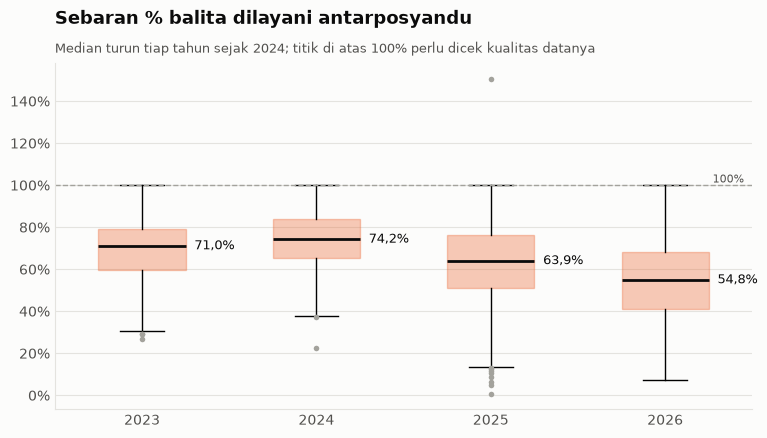

In [11]:
# Gambar 7 (pendukung) - boxplot sebaran % dilayani balita antarposyandu
pp = (JAN_AGU[JAN_AGU["Kategori"] == "Bayi Balita"]
      .groupby(["Tahun", "Posyandu_ID"])[["Sasaran", "Cakupan"]].sum().reset_index())
pp["Pct"] = pct(pp["Cakupan"], pp["Sasaran"])
tahun = [2023, 2024, 2025, 2026]
data_box = [pp.loc[pp["Tahun"] == t, "Pct"].dropna() for t in tahun]
fig, ax = plt.subplots(figsize=(9, 4.5))
bp = ax.boxplot(data_box, patch_artist=True, widths=0.5,
                medianprops=dict(color=TEXT_1, lw=2),
                flierprops=dict(marker="o", markersize=4, markerfacecolor=ABU, markeredgecolor="none"))
ax.set_xticks(range(1, len(tahun) + 1), [str(t) for t in tahun])  # aman untuk semua versi matplotlib
for b in bp["boxes"]:
    b.set(facecolor=WARNA["Bayi Balita"], alpha=0.35, edgecolor=WARNA["Bayi Balita"])
ax.axhline(100, color=ABU, ls="--", lw=1)
ax.text(4.45, 100, "100%", va="bottom", ha="right", fontsize=8, color=TEXT_2)
for i, d in enumerate(data_box, start=1):
    ax.text(i + 0.3, d.median(), f"{id_num(d.median())}%", va="center", fontsize=9, color=TEXT_1)
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.grid(axis="x", visible=False)
ax.set_title("Sebaran % balita dilayani antarposyandu", pad=28)
subjudul(ax, "Median turun tiap tahun sejak 2024; titik di atas 100% perlu dicek kualitas datanya")
simpan_fig(fig, "07_boxplot_balita.png")
plt.show()

## 10. Dashboard ringkasan (versi Python)
Versi statis dari dashboard Tableau, untuk README dan dokumentasi GitHub. Dashboard interaktif tetap di file Tableau.

✔ outputs\figures\00_dashboard_python.png


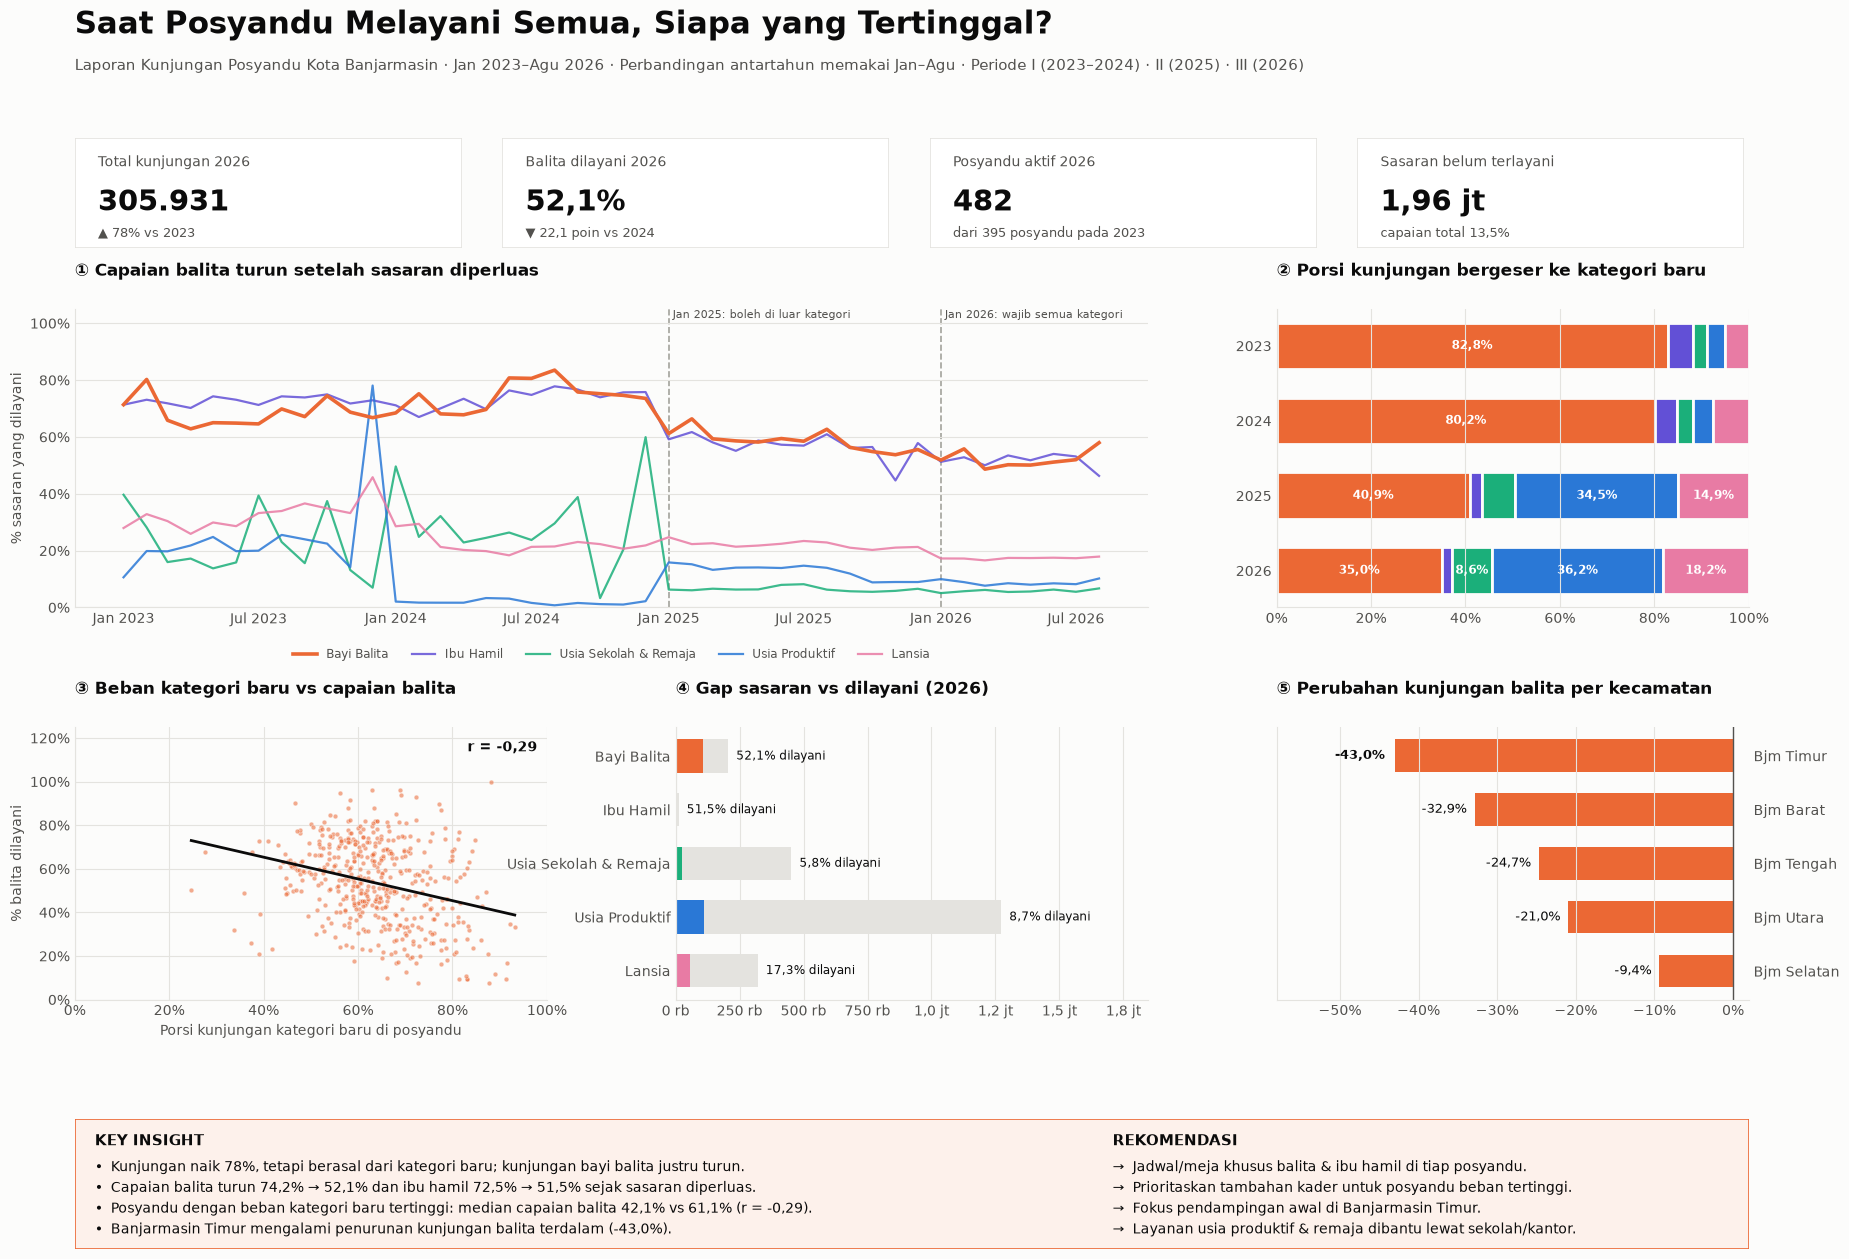

In [12]:
# Dashboard statis (versi Python dari dashboard Tableau) untuk README / GitHub
fig = plt.figure(figsize=(18, 13))
gs = fig.add_gridspec(4, 6, height_ratios=[0.55, 2.3, 2.1, 1.0], hspace=0.62, wspace=0.75,
                      left=0.04, right=0.97, top=0.9, bottom=0.03)

fig.text(0.04, 0.965, "Saat Posyandu Melayani Semua, Siapa yang Tertinggal?",
         fontsize=22, fontweight="bold", color=TEXT_1)
fig.text(0.04, 0.937, "Laporan Kunjungan Posyandu Kota Banjarmasin · Jan 2023–Agu 2026 · "
         "Perbandingan antartahun memakai Jan–Agu · Periode I (2023–2024) · II (2025) · III (2026)",
         fontsize=10.5, color=TEXT_2)

kpi = [
    ("Total kunjungan 2026", id_num(K["kunjungan_2026"], 0), f"▲ {id_num(K['naik_kunjungan'],0)}% vs 2023"),
    ("Balita dilayani 2026", f"{id_num(K['balita_2026'])}%", f"▼ {id_num(K['balita_2024']-K['balita_2026'])} poin vs 2024"),
    ("Posyandu aktif 2026", id_num(K["posyandu_aktif_2026"], 0), f"dari {K['posyandu_2023']} posyandu pada 2023"),
    ("Sasaran belum terlayani", f"{id_num(K['gap_2026']/1e6, 2)} jt", f"capaian total {id_num(K['pct_2026'])}%"),
]
for i, (lab, val, sub) in enumerate(kpi):
    ax = fig.add_axes([0.04 + i * 0.2375, 0.80, 0.215, 0.085])
    ax.set_axis_off()
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, transform=ax.transAxes, facecolor="white",
                               edgecolor=GRID, lw=1.2))
    ax.text(0.06, 0.74, lab, fontsize=10, color=TEXT_2, transform=ax.transAxes)
    ax.text(0.06, 0.34, val, fontsize=21, fontweight="bold", color=TEXT_1, transform=ax.transAxes)
    ax.text(0.06, 0.1, sub, fontsize=9, color=TEXT_2, transform=ax.transAxes)

ax1 = fig.add_subplot(gs[1, :4])
plot_tren(ax1, ringkas=True)
ax1.set_title("① Capaian balita turun setelah sasaran diperluas", pad=24, fontsize=12)
ax1.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.1), fontsize=8.5)

ax2 = fig.add_subplot(gs[1, 4:])
plot_komposisi(ax2, label_min=8)
ax2.set_title("② Porsi kunjungan bergeser ke kategori baru", pad=24, fontsize=12)

ax3 = fig.add_subplot(gs[2, :2])
plot_scatter(ax3, ringkas=True)
ax3.set_title("③ Beban kategori baru vs capaian balita", pad=24, fontsize=12)

ax4 = fig.add_subplot(gs[2, 2:4])
plot_gap(ax4, ringkas=True)
ax4.set_title("④ Gap sasaran vs dilayani (2026)", pad=24, fontsize=12)

ax5 = fig.add_subplot(gs[2, 4:])
ch = plot_kecamatan(ax5)
ax5.set_title("⑤ Perubahan kunjungan balita per kecamatan", pad=24, fontsize=12)

axi = fig.add_subplot(gs[3, :]); axi.set_axis_off()
axi.add_patch(plt.Rectangle((0, 0), 1, 1, transform=axi.transAxes, facecolor="#fdf1eb",
                            edgecolor=WARNA["Bayi Balita"], lw=1.2))
axi.text(0.012, 0.8, "KEY INSIGHT", fontsize=11, fontweight="bold", color=TEXT_1, transform=axi.transAxes)
insight = [
    f"Kunjungan naik {id_num(K['naik_kunjungan'],0)}%, tetapi berasal dari kategori baru; kunjungan bayi balita justru turun.",
    f"Capaian balita turun {id_num(K['balita_2024'])}% → {id_num(K['balita_2026'])}% dan ibu hamil "
    f"{id_num(K['bumil_2024'])}% → {id_num(K['bumil_2026'])}% sejak sasaran diperluas.",
    f"Posyandu dengan beban kategori baru tertinggi: median capaian balita {id_num(K['q4'])}% vs {id_num(K['q1'])}% (r = {id_num(K['r_2026'],2)}).",
    f"{ch.index[0]} mengalami penurunan kunjungan balita terdalam ({id_num(ch.iloc[0])}%).",
]
for i, t in enumerate(insight):
    axi.text(0.012, 0.6 - i * 0.16, "•  " + t, fontsize=10, color=TEXT_1, transform=axi.transAxes)
axi.text(0.62, 0.8, "REKOMENDASI", fontsize=11, fontweight="bold", color=TEXT_1, transform=axi.transAxes)
for i, t in enumerate(["Jadwal/meja khusus balita & ibu hamil di tiap posyandu.",
                       "Prioritaskan tambahan kader untuk posyandu beban tertinggi.",
                       f"Fokus pendampingan awal di {ch.index[0]}.",
                       "Layanan usia produktif & remaja dibantu lewat sekolah/kantor."]):
    axi.text(0.62, 0.6 - i * 0.16, "→  " + t, fontsize=10, color=TEXT_1, transform=axi.transAxes)

simpan_fig(fig, "00_dashboard_python.png")
plt.show()